# Laboratory 2 — REINFORCE and DQN
Complete all `TODO` functions. Use the lab handout for requirements. Start with a small number of episodes when debugging.

## What is this lab about (simple explanation)

**Reinforcement Learning (RL)** is how you train a dog: the agent tries something, gets a reward (a treat) or nothing, and slowly learns what to do to get more treats.

**CartPole** is our "game". There is a cart with a stick standing on it, and the agent pushes the cart **left or right** so the stick doesn't fall. It gets **+1 point for every step** the stick is still up, and the max is 500. The agent sees 4 numbers: where the cart is, how fast it moves, the stick's angle, and how fast the stick is falling.

**Return** = all the points you get from now until the end of the game. Points that come later count a little less (×0.99 each step, this is **gamma**), because "a treat now is better than a treat later".

**Two ways to teach the agent:**

1. **REINFORCE (policy gradient).** The network directly says "push left with 70% chance, right with 30%". The agent plays a **whole game**, then looks back: the moves that came before a high score get a higher chance next time, and the moves before a low score get a lower one. It's simple, but very noisy, like judging a football player only by the final score of the match.

2. **DQN (Deep Q-Network).** The network doesn't give chances. It gives a **score for each move** (a Q-value): "if you push left now, you'll get about 80 more points, if right, about 120". The agent just picks the move with the higher score. It learns **after every step** by using its own guess about the next step (this is called **bootstrapping**), so it doesn't wait for the game to end. Two tricks make it work:
   - **Replay buffer** is a memory of old moves. The agent studies random old moves from it, not only the latest ones (like revising random pages, not just the last one).
   - **Target network** is a frozen copy of the network that is used to compute the "correct answer". If the answer changed after every update, it would be like aiming at a target that keeps moving.
   - **Epsilon-greedy:** at the beginning the agent mostly moves randomly to explore, and later it mostly picks the best move.

**In short:** REINFORCE learns *what to do* (chances of moves) after the whole game. DQN learns *how good each move is* after every step, and then picks the best one.

In [1]:
import random, collections
import numpy as np
import torch
from torch import nn
from torch.distributions import Categorical
import gymnasium as gym
import matplotlib.pyplot as plt

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(42)

## Part A — REINFORCE

In [2]:
class PolicyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4, 32), nn.ReLU(), nn.Linear(32, 2))
    def forward(self, x):
        return torch.softmax(self.net(x), dim=-1)

def discounted_returns(rewards, gamma=0.99):
    # TODO: work backwards through rewards, return torch.float32 tensor
    returns = []
    G = 0.0
    for r in reversed(rewards):   # go from the last reward to the first
        G = r + gamma * G         # G_t = r_t + gamma * G_(t+1)
        returns.append(G)
    returns.reverse()             # flip back to normal time order
    return torch.tensor(returns, dtype=torch.float32)

def policy_loss(log_probs, returns):
    # TODO: sum negative log probability weighted by return
    # minus because optimizer minimizes, but we want to maximize the return
    return -(torch.stack(log_probs) * returns).sum()

In [3]:
assert torch.allclose(discounted_returns([1., 0., 2.], 0.9), torch.tensor([2.62, 1.8, 2.0]), atol=1e-5)
print("REINFORCE returns test passed")

REINFORCE returns test passed


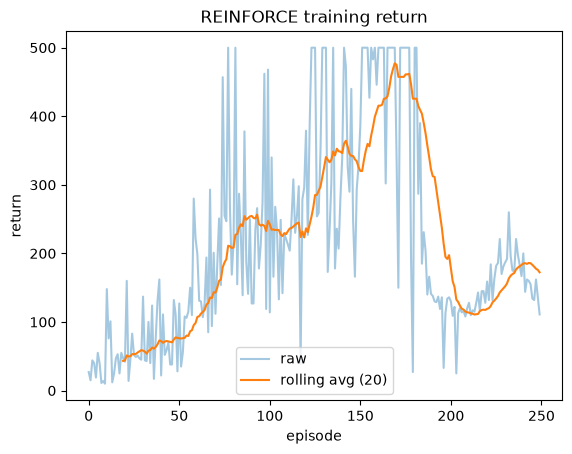

In [4]:
def train_reinforce(seed=42, episodes=250):
    set_seed(seed); env=gym.make("CartPole-v1"); env.reset(seed=seed); env.action_space.seed(seed)
    model=PolicyNet(); opt=torch.optim.Adam(model.parameters(),lr=0.01); scores=[]
    for ep in range(episodes):
        obs,_=env.reset(); done=False; rewards=[]; log_probs=[]
        while not done:
            probs=model(torch.tensor(obs,dtype=torch.float32))
            dist=Categorical(probs); action=dist.sample()
            obs,r,terminated,truncated,_=env.step(int(action.item()))
            log_probs.append(dist.log_prob(action)); rewards.append(float(r))
            done=terminated or truncated
        returns=discounted_returns(rewards,0.99)
        loss=policy_loss(log_probs,returns)
        opt.zero_grad();loss.backward();opt.step()
        scores.append(sum(rewards))
    env.close();return model,scores

model_pg, scores_pg = train_reinforce()
rolling_pg = np.convolve(scores_pg, np.ones(20) / 20, mode="valid")  # rolling average over 20 episodes
plt.plot(scores_pg, alpha=0.4, label="raw")
plt.plot(range(19, len(scores_pg)), rolling_pg, label="rolling avg (20)")
plt.xlabel("episode"); plt.ylabel("return"); plt.legend()
plt.title("REINFORCE training return"); plt.show()

## Part B — DQN

In [5]:
class QNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(4,64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,2))
    def forward(self,x):return self.net(x)

def dqn_targets(rewards,next_q_max,dones,gamma=0.99):
    # TODO: use terminal mask (1-dones)
    # if done=1 there is no next state, so target is just the reward
    return rewards + gamma * (1 - dones) * next_q_max

assert torch.allclose(dqn_targets(torch.tensor([1.,1.]),torch.tensor([5.,5.]),torch.tensor([0.,1.]),0.9),torch.tensor([5.5,1.]))
print("DQN target test passed")

DQN target test passed


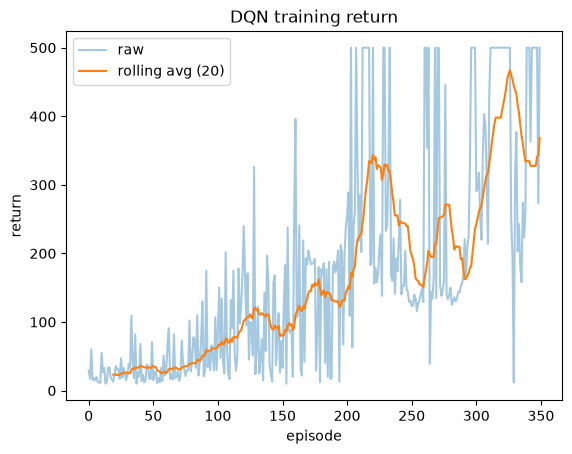

In [6]:
def train_dqn(seed=42,episodes=350):
    set_seed(seed);env=gym.make("CartPole-v1");env.reset(seed=seed);env.action_space.seed(seed)
    online=QNet();target=QNet();target.load_state_dict(online.state_dict())
    opt=torch.optim.Adam(online.parameters(),lr=1e-3)
    buffer=collections.deque(maxlen=10000);scores=[];step=0
    for ep in range(episodes):
        obs,_=env.reset();done=False;total=0
        while not done:
            epsilon=max(0.05,1.0-ep/250)
            if random.random()<epsilon: action=env.action_space.sample()
            else:
                with torch.no_grad(): action=int(online(torch.tensor(obs,dtype=torch.float32)).argmax().item())
            next_obs,reward,terminated,truncated,_=env.step(action)
            done=terminated or truncated
            # For this beginner lab, end-of-episode transitions are masked.
            buffer.append((obs.copy(),action,float(reward),next_obs.copy(),float(done)))
            obs=next_obs;total+=reward;step+=1
            if len(buffer)>=64:
                batch=random.sample(buffer,64)
                states=torch.tensor(np.array([x[0] for x in batch]),dtype=torch.float32)
                actions=torch.tensor([x[1] for x in batch],dtype=torch.long)
                rewards=torch.tensor([x[2] for x in batch],dtype=torch.float32)
                next_states=torch.tensor(np.array([x[3] for x in batch]),dtype=torch.float32)
                dones=torch.tensor([x[4] for x in batch],dtype=torch.float32)
                # TODO: compute selected Q(s,a), target max Q(s',a'), and MSE loss
                # Use torch.no_grad() for target values; use dqn_targets(...)
                q_sa = online(states).gather(1, actions.unsqueeze(1)).squeeze(1)  # Q of the action we took
                with torch.no_grad():
                    next_q_max = target(next_states).max(dim=1).values  # best Q in next state (target net)
                    y = dqn_targets(rewards, next_q_max, dones, 0.99)
                loss = nn.functional.mse_loss(q_sa, y)
                opt.zero_grad(); loss.backward(); opt.step()
            if step%200==0: target.load_state_dict(online.state_dict())
        scores.append(total)
    env.close();return online,scores

model_dqn,scores_dqn=train_dqn()
rolling_dqn = np.convolve(scores_dqn, np.ones(20) / 20, mode="valid")
plt.plot(scores_dqn, alpha=0.4, label="raw")
plt.plot(range(19, len(scores_dqn)), rolling_dqn, label="rolling avg (20)")
plt.xlabel("episode"); plt.ylabel("return"); plt.legend()
plt.title("DQN training return"); plt.show()

In [7]:
# Question 5: run three seeds and compare the last 20 episode returns
seeds = [42, 0, 1]
pg_last, dqn_last = [], []
for s in seeds:
    _, sc_pg = train_reinforce(seed=s)
    _, sc_dqn = train_dqn(seed=s)
    pg_last.append(np.mean(sc_pg[-20:]))
    dqn_last.append(np.mean(sc_dqn[-20:]))
    print(f"seed {s}: REINFORCE = {pg_last[-1]:.1f}, DQN = {dqn_last[-1]:.1f}")
print(f"mean over seeds: REINFORCE = {np.mean(pg_last):.1f} (std {np.std(pg_last):.1f}), "
      f"DQN = {np.mean(dqn_last):.1f} (std {np.std(dqn_last):.1f})")

seed 42: REINFORCE = 172.4, DQN = 368.6


seed 0: REINFORCE = 83.2, DQN = 395.4


seed 1: REINFORCE = 172.1, DQN = 145.7
mean over seeds: REINFORCE = 142.6 (std 42.0), DQN = 303.2 (std 111.9)


## Reflection
1. Which network outputs probabilities and which outputs Q-values?
2. Why is REINFORCE a complete-episode algorithm?
3. Why is DQN bootstrapping?
4. What are replay buffer and target network for?
5. Run three seeds and compare the last 20 episode returns.

### My answers

**1.** `PolicyNet` outputs **probabilities** of the 2 actions (it has softmax at the end). `QNet` outputs **Q-values**, one number per action, with no softmax (they can be any number).

**2.** REINFORCE needs the full return $G_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \dots$, and you only know it when the episode is finished. It has no value function to guess the future, so it waits for the end of the episode (Monte Carlo) and then does one update.

**3.** The DQN target is $y = r + \gamma (1-\text{done}) \max_{a'} Q_{target}(s',a')$. It uses its **own estimate** of the next state instead of the real future rewards, which is what bootstrapping means. If the transition is terminal (done = 1), the second part becomes 0 and $y = r$.

**4.** The **replay buffer** stores old transitions, and we train on random mini-batches from it. This breaks the correlation between steps that come one after another, and every transition can be used many times. The **target network** is a copy of the Q-network that is updated only every 200 steps, so the target doesn't change after every update and we don't chase a moving target. Both make training more stable.

**5.** Mean return of the last 20 episodes:

| seed | REINFORCE | DQN |
|---|---|---|
| 42 | 172.4 | 368.6 |
| 0 | 83.2 | 395.4 |
| 1 | 172.1 | 145.7 |
| **mean (std)** | **142.6 (42.0)** | **303.2 (111.9)** |

In my runs DQN got a higher mean, but there are only 3 seeds and the results jump a lot between seeds (seed 1 of DQN is only 145.7), so I can't say DQN is always better. REINFORCE learns fast at the start, but its curve is very noisy and can suddenly drop, because the full-episode return has high variance. DQN is slow at the start because ε is big (lots of random actions), and it gets better once ε gets small. Also, DQN trains for 350 episodes and REINFORCE for 250, so the comparison isn't fully equal.